# fMRI オープンデータ解析講習：脳のパターンから課題を当てる（デコーディング）

01 では、GLM で「どこが反応したか」を調べました。ここでは向きを逆にして、脳の活動のパターンから、その人が顔条件と図形条件の
どちらを行っていたかを当てます。脳の活動から課題や刺激を当てる解析を **デコーディング** と呼びます。

使うのは、機械学習の **分類器** です。分類器は、例（ここでは脳のパターン）と正解（顔か図形か）の組をたくさん見せると、
新しい例の正解を予想できるようになる仕組みです。例を見せて予想のしかたを決めることを **学習**、学習に使っていない例で
予想を試すことを **テスト** と呼びます。ここでは、ほかの人たちの脳で学習した分類器で、**一度も見ていない人** の課題を当てます。

- **ゴール 3**：初めて見る人の課題を当て、それが偶然では説明しにくいことを確かめる（4・5 章）

**始める前に**：01 のタブで、メニューの「ランタイム」→「ランタイムを接続解除して削除」を選んでから、このノートブックを
実行してください。Colab の無料枠では、同時に使えるメモリなどに限りがあるためです。

### このノートブックの読み方

左に縦線の付いていない文がメインの文章です。左に縦線が付いた「**くわしく**」は、時間があるときや、
あとで読むための部分で、講習の間は読み飛ばしてかまいません。コードは、1 行ずつ読めなくてかまいません。

### Colab での使い方

- セルを選んで **Shift + Enter** で実行します。**上から順に**実行してください。左に回る印が出ている間は、実行中です。
- 赤い文字（エラー）が出たら、上のセルを飛ばしていないかを確かめ、メニューの「ランタイム」→「すべてのセルを実行」を
  試してください。

> **くわしく**（時間があれば）
>
> - 01 を済ませていなくても、このノートブックだけで動きます。
> - メインの文章だけを読めば、流れが分かるように書いてあります。
> - 接続が切れると、取ってきたデータも消えます。そのときも「ランタイム」→「すべてのセルを実行」で、最初からやり直せます。
> - エラーの `NameError` は、たいてい上のセルを実行していないときに出ます。
> - GPU は使いません。

## 0. 準備

脳画像の解析と表示のための Python のライブラリ **Nilearn** を入れます。01 と同じバージョンです。
「restart the kernel」という表示が出ても、そのまま次へ進んでかまいません。

0 章の 3 つのセルは、続けて実行するだけでかまいません。

In [ ]:
%pip install -q nilearn==0.13.1

使う道具を読み込みます。

In [ ]:
import socket
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from nilearn import masking, plotting
from nilearn.maskers import NiftiMasker
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict, cross_val_score
from sklearn.svm import SVC

socket.setdefaulttimeout(60)  # 取得の途中で通信が 60 秒止まったら、やり直す

Nilearn が出す注意書きのうち、今回の解析では気にしなくてよいものを表示しないようにします。

In [ ]:
import warnings

warnings.filterwarnings("ignore", message=".*confounds will be standardized.*")

> **くわしく**（時間があれば）
>
> 分類器には、Colab に最初から入っている機械学習のライブラリ **scikit-learn** を使います。

## 1. 課題とデータ

01 と同じ **AOMIC PIOP1**（OpenNeuro の番号 ds002785）の **表情マッチング課題** を使います。

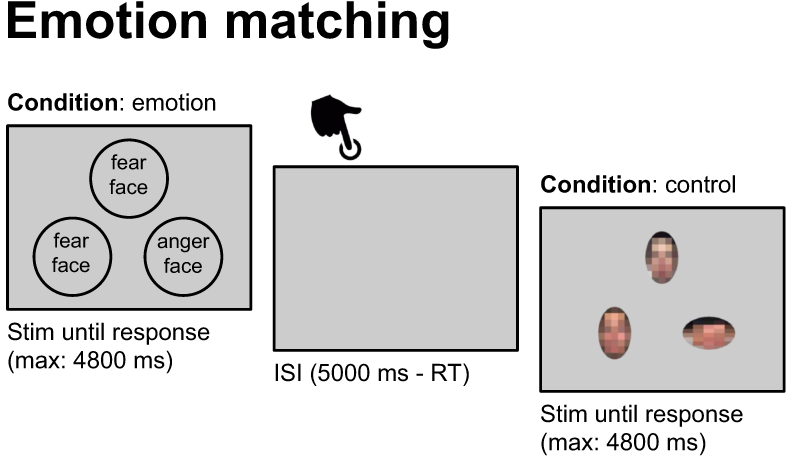

図：Snoek et al. (2021) の Fig. 2 の一部（CC BY 4.0）。左が顔条件、右が図形条件の画面です（実際には、顔条件では円の代わりに
顔のカラー写真が出ます）。

- **emotion（顔条件）**：上の顔と同じ表情（怒りか恐れ）の顔を、下の 2 枚から選びます。
- **control（図形条件）**：上の楕円と同じ向き（縦長か横長か）の楕円を、下の 2 つから選びます。楕円は顔の写真を
  モザイク状にして作ってあり、色と大きさは顔の写真とそろえてあります。
- 試行は 5 秒ごとに始まります。同じ条件が 6 試行（30 秒）続く **ブロック** が、control → emotion → control → … と
  交互に 8 つ並びます（全員が同じ順番です）。

今回は **20 人分**、合わせて約 2.2 GB を使います。次のセルは、取ってくる人と手順を決めます（実行するだけでかまいません）。

In [ ]:
subjects = [f"sub-{i:04d}" for i in range(1, 21)]  # sub-0001 から sub-0020 までの 20 人。8 章で人数を減らして試せます
print(len(subjects), "people")

base = "https://s3.amazonaws.com/openneuro.org/ds002785"  # OpenNeuro の ds002785 の置き場所


def fetch(subject):
    """1 人分の 4 つのファイルを取ってきて、置き場所を返す。すでに取ってあるファイルは取り直さない。通信が切れたら 3 回まで試す"""
    prefix = f"{subject}_task-emomatching_acq-seq"
    fmriprep = f"{base}/derivatives/fmriprep/{subject}/func/{prefix}"
    urls = {
        "bold": f"{fmriprep}_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz",  # 脳画像（前処理の結果）
        "mask": f"{fmriprep}_space-MNI152NLin2009cAsym_desc-brain_mask.nii.gz",  # 脳の範囲（前処理の結果）
        "confounds": f"{fmriprep}_desc-confounds_regressors.tsv",  # 頭の動きなど（前処理の結果）
        "events": f"{base}/{subject}/func/{prefix}_events.tsv",  # 課題の記録（元のデータ）
    }
    data_dir = Path("data") / subject
    data_dir.mkdir(parents=True, exist_ok=True)
    paths = {}
    for name, url in urls.items():
        path = data_dir / url.rsplit("/", 1)[1]
        if not path.exists():
            part = path.with_name(path.name + ".part")  # 途中で切れても壊れたファイルが残らないように
            for attempt in range(3):
                try:
                    urllib.request.urlretrieve(url, part)
                    break
                except OSError:
                    if attempt == 2:
                        raise
                    time.sleep(2)
            part.rename(path)
        paths[name] = path
    return paths

全員分を順に取ってきます。数分かかります。待つ間に、2 章を読み進めてください。

In [ ]:
files = {}
for subject in subjects:
    files[subject] = fetch(subject)
    print(subject, end=" ")

> **くわしく**（時間があれば）
>
> - データセットのページ：https://openneuro.org/datasets/ds002785 （誰でも自由に使える条件、CC0 で公開されています）
> - 課題の図は、Snoek et al. (2021) の Fig. 2 から、表情マッチング課題の部分を切り出したものです。真ん中は、答えたあとの空白の画面です。
> - 01 と同じく、データを集めた研究者が fMRIPrep で前処理し、OpenNeuro の同じデータセットに置いた結果
>   （`derivatives/fmriprep/`）を使います（01 の 1 章の図の下の段）。
> - 1 人あたり約 110 MB です。データはインターネットから Colab のサーバーに直接届きます。

## 2. 1 人分のデータを「パターン」にする

分類器に渡すのは、**表** です。1 行が 1 つの例（ここでは 1 つのブロック）、1 列が 1 つの特徴（ここでは 1 つのボクセル）です。
1 行に並んだ数字の並び、つまり「そのとき脳のどこがどれだけ活動していたか」を、ここでは **パターン** と呼びます。

まず、全員に共通する脳の範囲（マスク）を決めます。全員のマスクのどれにも入っているボクセルだけを使います。

In [ ]:
mask = masking.intersect_masks([files[s]["mask"] for s in subjects], threshold=1)
print("voxels in the mask:", int(mask.get_fdata().sum()))

> **くわしく**（時間があれば）
>
> 全員の共通部分にするのは、表の列を全員でそろえるためです。ある人では脳の外になるボクセルを入れると、その列の意味が
> 人によって変わってしまいます。

脳画像を、時間 × ボクセルの表に変えます。そのときに、ゆっくりした信号の変化（ドリフト）と、頭の動きで説明できる変化を
取り除き、ボクセルごとに値の大きさをそろえます。

In [ ]:
masker = NiftiMasker(mask_img=mask, detrend=True, standardize="zscore_sample").fit()
motion_columns = ["trans_x", "trans_y", "trans_z", "rot_x", "rot_y", "rot_z"]

first = files[subjects[0]]
motion = pd.read_csv(first["confounds"], sep="\t")[motion_columns]
table = masker.transform(first["bold"], confounds=motion)
print("table (volumes, voxels):", table.shape)

> **くわしく**（時間があれば）
>
> `NiftiMasker` が、脳画像を表に変える道具です。
>
> - `detrend=True`：ゆっくりした直線的な信号の変化（ドリフト）を取り除く
> - `standardize="zscore_sample"`：ボクセルごとに、平均 0、標準偏差 1 にそろえる（人やボクセルによる信号の大きさの違いをならす）
> - `confounds=motion`：頭の動き（平行移動 3 つと回転 3 つ）で説明できる変化を取り除く

135 枚（ボリューム）の脳画像が、それぞれ 1 行の数字の並びになりました。

次に、ブロックごとに、その間のボリュームを平均して 1 つのパターンにします。1 枚ずつを別々の例にしないのは、隣り合う
ボリュームどうしがとてもよく似ていて、別々に数えると例の数を水増ししてしまうからです。1 人から取れる例は 8 つ
（ブロックの数）になります。

血流の変化は神経の活動より数秒遅れるので（01 の HRF）、ブロックの時間を **6 秒** 後ろにずらし、ブロックの最初の
2 ボリュームは使いません。

In [ ]:
t_r = 2.0  # 撮る間隔（秒）
delay = 6.0  # 血流の遅れ（秒）
skip = 2  # ブロックの最初に使わないボリュームの数


def find_blocks(events, n_volumes):
    """ブロックごとに、条件と、平均に使うボリュームの番号を返す"""
    times = np.arange(n_volumes) * t_r - delay  # 各ボリュームの時刻から遅れの 6 秒を引く（ブロックを 6 秒後ろにずらすのと同じ）
    block_number = (events["trial_type"] != events["trial_type"].shift()).cumsum()  # 同じ条件が続く間は同じ番号
    blocks = []
    for _, trials in events.groupby(block_number):
        start = trials["onset"].min()  # 最初の試行が始まった時刻
        end = trials["onset"].max() + 5.0  # 最後の試行が終わった時刻
        volumes = np.where((times >= start) & (times < end))[0][skip:]
        blocks.append((trials["trial_type"].iloc[0], volumes))
    return blocks


events = pd.read_csv(first["events"], sep="\t")
blocks = find_blocks(events, len(table))
for trial_type, volumes in blocks:
    print(f"{trial_type:8s} volumes {volumes[0]:3d}-{volumes[-1]:3d} ({len(volumes)} volumes)")

図にすると、こうなります。帯がブロックの時間、点が平均に使うボリュームの時刻です（オレンジ：emotion、青：control）。
点は、帯より遅れて始まり、遅れて終わります。

In [ ]:
colors = {"emotion": "tab:orange", "control": "tab:blue"}
fig, ax = plt.subplots(figsize=(10, 1.5))
for onset, trial_type in zip(events["onset"], events["trial_type"]):
    ax.axvspan(onset, onset + 5, color=colors[trial_type], alpha=0.3)
for trial_type, volumes in blocks:
    ax.scatter(volumes * t_r, np.zeros(len(volumes)), color=colors[trial_type], s=12)
ax.set_xlim(0, len(table) * t_r)
ax.set_yticks([])
ax.set_xlabel("time (s)")
plt.show()

> **くわしく**（時間があれば）
>
> - 帯の中の細い縦線は、5 秒ごとの試行の区切りです。点の始まりが帯の始まりより 10 秒ほど遅いのは、血流の遅れ（6 秒）と、
>   ブロックの最初の 2 ボリューム（4 秒）を使わない分です。点の終わりは、帯の終わりより 6 秒ほど遅れます。
> - ブロックの最初の 2 ボリュームを使わないのは、前のブロックへの反応がまだ残っているためです。
> - ブロックの中で平均すると、雑音も減ります。

ここまでをまとめて、1 人分のデータから 8 つのパターンを作る関数にし、1 人目で試します。

In [ ]:
def block_patterns(paths):
    """1 人分のデータから、ブロックごとの平均のパターン（8 個）と、その種類を返す"""
    motion = pd.read_csv(paths["confounds"], sep="\t")[motion_columns]
    table = masker.transform(paths["bold"], confounds=motion)
    events = pd.read_csv(paths["events"], sep="\t")
    patterns, labels = [], []
    for trial_type, volumes in find_blocks(events, len(table)):
        patterns.append(table[volumes].mean(axis=0))
        labels.append(trial_type)
    return np.array(patterns), np.array(labels)


patterns, labels = block_patterns(first)
print("patterns (blocks, voxels):", patterns.shape)
print("labels:", labels)

1 つのパターンを、脳の画像に戻して見てみます。2 番目のブロック（顔条件）です。赤はその人の平均より活動が高い場所、
青は低い場所です。これが、分類器に渡す例の 1 つです。ほとんど雑音に見えて、見ただけでは顔か図形かは分かりません。
分類器は、こうした例をたくさん見て、見分けるための重みを決めます。

In [ ]:
plotting.plot_stat_map(masker.inverse_transform(patterns[1]), display_mode="z", cut_coords=8,
                       title=f"{subjects[0]}, block 2 ({labels[1]})")
plotting.show()

## 3. 全員分のパターンを集める

全員分で同じことをして、1 つの表にまとめます。1 分ほどかかります。20 人 × 8 ブロックで、160 行の表になります。

In [ ]:
X_list, y_list, groups_list = [], [], []
for subject in subjects:
    patterns, labels = block_patterns(files[subject])
    X_list.append(patterns)
    y_list.append(labels)
    groups_list.append(np.full(len(labels), subject))
    print(subject, end=" ")

X = np.vstack(X_list)
y = np.concatenate(y_list)
groups = np.concatenate(groups_list)
print()
print("X:", X.shape)
print("y:", pd.Series(y).value_counts().to_dict())

> **くわしく**（時間があれば）
>
> - `X`：パターンの表（20 人なら 20 × 8 ブロック ＝ 160 行）
> - `y`：それぞれの行の正解（emotion か control）
> - `groups`：それぞれの行が誰のデータか

## 4. ほかの人で学習し、初めて見る人で当てる（ゴール 3）

分類器には、**線形 SVM**（サポートベクターマシン）を使います。線形 SVM は、ボクセルごとの重みを学習し、
「パターン × 重み」の合計が正なら一方、負ならもう一方と判定します。

まず、1 人目（sub-0001）を **テスト用** に取っておき、残りの 19 人で学習します（`fit`）。
そのあと、学習に一度も使っていない 1 人目の 8 ブロックを当てます（`predict`）。

In [ ]:
test_subject = subjects[0]
train = groups != test_subject  # 学習に使う行（1 人目以外）。~train は「train でない行」、つまりテストの人の行

svm = SVC(kernel="linear", C=1.0)
svm.fit(X[train], y[train])
predicted = svm.predict(X[~train])
pd.DataFrame({"truth": y[~train], "predicted": predicted})

In [ ]:
print("accuracy:", (predicted == y[~train]).mean())

1 人だけでは、たまたまかもしれません。そこで、テスト用の人を 1 人ずつ入れ替えて、全員について同じことをします。
これを **交差検証** と呼びます（ここでは「1 人除き」の交差検証）。

大事なのは、**テストする人のパターンと正解を、学習に一切使わない** ことです。同じ人のデータが学習に入っていると、
その人の脳の形や癖を覚えて当ててしまい、正解率が実力より高く出ます。

次のセルは、計算を速くする工夫です。答えは同じで、ずっと速くなります（実行するだけでかまいません）。

In [ ]:
K = X @ X.T  # 行の数 × 行の数（20 人なら 160 × 160）の内積の表

svm_k = SVC(kernel="precomputed", C=1.0)
svm_k.fit(K[train][:, train], y[train])  # 学習の人どうしの内積
same = np.array_equal(svm_k.predict(K[~train][:, train]), predicted)  # テストの人 × 学習の人の内積
print("same predictions as above:", same)

> **くわしく**（時間があれば）
>
> - 2 章のマスクだけは、脳の範囲を決めるために全員分から作りました。正解のラベルは使っていません。
> - 速くする工夫：このあと学習を何千回も繰り返します。線形 SVM の計算に使うのは、実はパターンどうしの **内積**
>   （2 つのパターンの数字を掛けて足したもの。似ているほど大きい）だけです。そこで、160 × 160 の内積の表を最初に 1 回だけ
>   作っておきます（`kernel="precomputed"`）。
> - 線形 SVM の重みは、2 種類の例をできるだけ余裕をもって分けられるように決めます。

全員で交差検証をします。下の棒グラフは、棒 1 本が 1 人です。その人をテストに回したとき、8 ブロックのうち何割を
当てたかを示します。

In [ ]:
cv = LeaveOneGroupOut()  # 1 人ずつテストに回す
scores = cross_val_score(svm_k, K, y, groups=groups, cv=cv)
print("mean accuracy:", scores.mean().round(3))

fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(subjects, scores)
ax.axhline(0.5, color="gray", linestyle="--", label="chance (0.5)")
ax.set_ylabel("accuracy")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=90)
ax.legend(loc="lower right")
plt.show()

> **くわしく**（時間があれば）
>
> 8 ブロックなので、1 人ずつの値は 0.75、0.875、1 のように飛び飛びになります。

## 5. 偶然でもこのくらい当たるのでは？（ラベルを入れ替える）

2 択なので、でたらめに答えても半分（0.5）は当たります。ただし、例が少ないと、偶然だけで 0.6 や 0.7 になることもあります。
そこで、「脳のパターンと課題の種類は無関係」だったらどのくらい当たるのかを、実際に作って比べます。

やり方は、**正解のラベルを入れ替えて**、まったく同じ手順（学習 → 初めての人で当てる）をやり直すことです。
**人ごとに、その人の 8 つのラベルの「顔」と「図形」をそっくり入れ替えるかどうかを、コインを投げるようにでたらめに
決めます**。

入れ替える関数を作ります（実行するだけでかまいません）。

In [ ]:
rng = np.random.default_rng(0)  # 乱数を使うところで、毎回同じ結果になるように


def flip_people(labels, groups):
    """人ごとに、その人の全部のラベルの 2 つの種類（顔と図形など）を入れ替えるかどうかを、でたらめに決める"""
    kind_a, kind_b = np.unique(labels)
    swapped = np.where(labels == kind_a, kind_b, kind_a)
    flip = {person: rng.random() < 0.5 for person in np.unique(groups)}
    return np.where([flip[g] for g in groups], swapped, labels)

まず 1 回やってみます。

In [ ]:
y_flipped = flip_people(y, groups)
print("people whose labels were swapped:", [s for s in subjects if (y_flipped[groups == s] != y[groups == s]).all()])
print("accuracy with swapped labels:", cross_val_score(svm_k, K, y_flipped, groups=groups, cv=cv).mean().round(3))

これを 1000 回繰り返すと、「偶然ならこのくらい」という正解率の分布ができます。本物の正解率がその分布のどこにあるかで、
偶然では説明しにくいかを判断します。これを **並べ替え検定**（permutation test）と呼びます。1〜2 分かかります。

In [ ]:
score = scores.mean()  # 4 章の本物の正解率
null_scores = np.array([cross_val_score(svm_k, K, flip_people(y, groups), groups=groups, cv=cv).mean()
                        for _ in range(1000)])
p_value = (np.sum(null_scores >= score) + 1) / (len(null_scores) + 1)
print("accuracy:", round(score, 3))
print("swapped labels: mean", null_scores.mean().round(3), "/ max", null_scores.max().round(3))
print("p =", round(p_value, 4))

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(null_scores, bins=30, color="gray", label="swapped labels (1000 times)")
ax.axvline(score, color="red", label=f"true labels ({score:.2f})")
ax.set_xlabel("accuracy")
ax.set_xlim(0, 1)
ax.legend(loc="upper left")
plt.show()

20 人のときは、入れ替えたラベルの正解率は 0.5 のまわりに散らばり、本物の正解率はその外にあります。p 値は、入れ替えたのに
本物と同じかそれ以上当たった割合です（1000 回なら、いちばん小さい値は約 0.001）。

ここで出た 2 つの数は、役割が違います。p 値は、「人をまたいで共通する顔と図形の違いが **ある** と言えるか」を見るものです。
「新しい 1 人を **どのくらい** 当てられるか」の見積もりは、4 章の交差検証の正解率のほうです。

ここまでで、本物の正解率と p 値が出ていれば、**ゴール 3** 達成です。

> **くわしく**（時間があれば）
>
> - p 値は、正確には「入れ替えたのに本物と同じかそれ以上当たった回数 ＋ 1」を「1000 ＋ 1」で割ったものです。本物のラベルの
>   付け方も、偶然ありえた付け方の 1 つとして数えるため、＋ 1 します。
> - 人ごとに入れ替えるのは、知りたいのが **人をまたいで共通する** 顔と図形の違いがあるかだからです。人をまたいで共通する
>   違いが無ければ、誰のラベルを入れ替えても、同じくらい当たるはずです。入れ替える関数は、7 章でも使うので、ラベルの 2 つの
>   種類が何であっても入れ替えられるようにしてあります。
> - 偶然でも 0.8 くらいまで当たることがあるのは、入れ替えた人と入れ替えなかった人の数が偏ると、多いほうの人たちのラベルの
>   付け方を学んで、その人たちを当てるためです。8 章の演習 2 で人数を変えたときは、ここに書いたことではなく、出てきた p 値で
>   判断してください。
> - どちらの数も、このデータと同じような人々（同じ装置、同じ課題）についての話です。別の施設や別の年齢層の人でも当たるかは、
>   別のデータで確かめる必要があります。

> **くわしく**（時間があれば）
>
> **統計に詳しい人へ**：正解した数をそのまま二項検定にかけたり、1 人ずつの正解率を t 検定にかけたりしないのは、
> 例どうしが独立でないためです。同じ人の 8 ブロックはたがいに似ていますし、20 回の学習はほとんど同じ 19 人ずつを使っています。
> 並べ替え検定は、学習と検証の手順ごと繰り返すので、こうした依存は分布に織り込まれます。ただし、「人をまたいで共通する
> 違いが無ければ、人ごとにラベルの顔と図形をそっくり入れ替えても同じように見えるはず」という前提（**交換可能性**）が要ります。
> 1 人の中で 8 ブロックのラベルをばらばらに混ぜる方法もありますが、それでは、1 人の中では一貫していても人をまたいでは
> 共通しない違いまで壊してしまい、p 値が小さく出すぎることがあります。また、この課題は全員が同じ順番で行ったので、
> 時間とともにゆっくり変わる信号が人をまたいで似ていると、課題と関係がなくても奇数番目と偶数番目のブロックに共通の違いが
> 生まれ、この前提が崩れます。7 章で、その手がかりを見ます。20 人での p 値は 0.05 よりずっと小さいので、交換可能性が
> 成り立つと仮定すれば、「この 20 人に共通する、顔条件と図形条件の脳のパターンの違いは無い」という仮説を退けられます。
> この前提はデータだけでは保証できないので、p 値はこの条件つきで読みます。

## 6. 当てるのに使われた場所（重みの地図）

20 人全員で学習し直し、ボクセルごとの重みを脳の画像に戻します。赤は「ここが高いと顔条件（emotion）と判定する」、
青は「ここが高いと図形条件（control）と判定する」場所です。

In [ ]:
svm.fit(X, y)
print("classes:", svm.classes_)  # 重みが正なら、2 番目（emotion）の側
weights = masker.inverse_transform(svm.coef_[0])
plotting.plot_stat_map(weights, display_mode="z", cut_coords=8, title="SVM weights (red: emotion)")
plotting.show()

In [ ]:
plotting.plot_glass_brain(weights, plot_abs=False, colorbar=True, title="SVM weights (red: emotion)")
plotting.show()

赤い重みは、後頭葉のいちばん後ろ（視覚野のあたり）と、両側の側頭葉の下側（紡錘状回のあたり）に集まっています。
どちらも、01 の GLM で顔条件に強く反応した場所と重なります。
比べるために、「顔のブロックの平均 − 図形のブロックの平均」の地図も描きます。

In [ ]:
difference = X[y == "emotion"].mean(axis=0) - X[y == "control"].mean(axis=0)
plotting.plot_glass_brain(masker.inverse_transform(difference), plot_abs=False, colorbar=True,
                          title="mean pattern: emotion - control")
plotting.show()

ただし、重みの地図は、「情報がある場所」の地図とは限りません。

> **くわしく**（時間があれば）
>
> - 後頭葉のいちばん後ろは後頭極と呼ばれ、目から入った映像を早い段階で処理する視覚野のあたりです。
> - 分類器は、雑音を打ち消すために、課題と関係のない場所にも重みを置くことがあります。どこに情報があるかを調べたいときは、
>   平均の差の地図（上）や、9 章のサーチライトなどの方法も合わせて見ます。

## 7. 何を手がかりに当てたのか

**考えてみましょう**：4 章では、初めて見る人の課題が、高い正解率で当たりました。分類器は、何を手がかりにしたのでしょうか。
表情を読み取った、と言ってよいでしょうか。

正解率が高いことから言えるのは、「この 2 つの課題を見分ける情報が、人をまたいで共通する形で脳にある」ことまでです。
それが **何の情報か** は、正解率だけでは分かりません。

- **見た目の違い**：顔条件と図形条件では、形（顔か楕円か）、表情の有無、答えるまでの時間などが違います。6 章の重みが
  視覚野に集まっていたことからも、分類器は主に「何を見ているか」の違いを手がかりにしていると考えられます。
- **順番**：この課題は、全員が同じ順番（図形 → 顔 → 図形 → 顔 → … の 8 ブロック）でした。撮像の間には信号がゆっくり
  変わっていくので、脳のパターンには「撮像の前のほうか後のほうか」の情報も含まれます（このあと確かめます）。もし分類器が、
  顔と図形の違いではなく「後のほうなら顔、前のほうなら図形」と答えていたら、前のほうの顔（2 番目）を図形と、後のほうの
  図形（7 番目）を顔と間違えるはずです。ブロックの位置ごとに正解率を見て確かめます。

「後のほうなら顔」と答えたときの当たり外れは、次のようになります。

| 位置 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
|---|---|---|---|---|---|---|---|---|
| 正解 | 図形 | 顔 | 図形 | 顔 | 図形 | 顔 | 図形 | 顔 |
| 「後のほうなら顔」と答えると | 図形 | 図形 | 図形 | 図形 | 顔 | 顔 | 顔 | 顔 |
| 合うか | ○ | × | ○ | × | × | ○ | × | ○ |

In [ ]:
predicted_all = cross_val_predict(svm_k, K, y, groups=groups, cv=cv)
check = pd.DataFrame({
    "position": np.tile(np.arange(1, 9), len(subjects)),  # 何番目のブロックか
    "truth": y,
    "correct": predicted_all == y,
})
check.groupby(["position", "truth"])["correct"].mean().round(2)

2 番目（前のほうの顔）も 7 番目（後のほうの図形）も、ほかの位置と同じくらい当たっています。分類器は、「前のほうか
後のほうか」で答えているのではないと考えられます。

> **くわしく**（時間があれば）
>
> - 楕円は顔の写真をモザイク状にして作ってあり、色と大きさはそろえてあります。答えるまでの時間は、01 で見た sub-0002 では
>   顔条件のほうが長くなっていました。
> - 重みは、分類器が実際に使った場所なので、「何を手がかりにしたか」を考えるのには使えます。6 章で注意したのは、重みの地図を
>   「情報がある場所」の地図として読むことです。
> - 「感情を読み取った」と言うには、例えば怒りの顔と恐れの顔を見分けられるかを調べる必要があります。

では、順番に関係する情報はまったく無いのでしょうか。課題とは関係なく、ブロックを「前半の 4 つ」と「後半の 4 つ」に
分けて、同じように当ててみます。20 秒ほどかかります。

In [ ]:
half = np.where(np.tile(np.arange(8), len(subjects)) < 4, "first half", "second half")
half_score = cross_val_score(svm_k, K, half, groups=groups, cv=cv).mean()
half_null = np.array([cross_val_score(svm_k, K, flip_people(half, groups), groups=groups, cv=cv).mean()
                      for _ in range(200)])
half_p = (np.sum(half_null >= half_score) + 1) / (len(half_null) + 1)
print("first half vs second half: accuracy", half_score.round(3), "/ swapped labels: max", half_null.max().round(3),
      "/ p =", round(half_p, 4))

20 人では、前半か後半かも、偶然よりは当たります。撮像のあいだにゆっくり変わっていく信号（装置の状態や、参加者の眠気、
課題への慣れなど）が、人をまたいで似ているためと考えられます。

課題の正解率は、前半か後半かよりずっと高いので、ゆっくりした変化だけでは説明しにくいです。ただし、全員が同じ順番
だったので、課題の違いと順番を、データの解析だけで完全に切り離すことはできません。それには、人によって順番を入れ替える
（**カウンターバランス**）など、実験の計画の段階での工夫が要ります。

当たったときほど、何で当たったのかを確かめる必要があります。

次の 03 では、このデコーディングを、ASD の人と定型の人の脳を比べる問いに使います。

> **くわしく**（時間があれば）
>
> - 比べる相手は、5 章と同じく、人ごとに「前半」と「後半」のラベルを入れ替えるかどうかをでたらめに決めて作りました。時間を
>   短くするため 200 回にしています（200 回なら、いちばん小さい p 値は約 0.005 です）。
> - 並べ替え検定で言えるのは「ラベルと関係する情報がある」ことまでで、**それが何の情報かは言えません**。
> - この課題では、奇数番目が図形、偶数番目が顔でした。課題の違いと「奇数番目か偶数番目か」が、完全に重なっています。

## 8. 自分で試してみよう

セルを書き換えて試せます。時間があれば試してください（持ち帰って試してもかまいません）。

> **くわしく**（時間があれば）
>
> 1. 下のセルで、学習に使う人数を 1, 2, 5, 10, 15 人と変えたとき、残りの人をどのくらい当てられるかを調べる（**学習曲線**）。
> 2. 1 章の `range(1, 21)` を `range(1, 6)`（5 人）や `range(1, 11)`（10 人）にして、メニューの「ランタイム」→
>    「すべてのセルを実行」でやり直す。正解率と p 値はどう変わるでしょうか。ヒント：5 人なら、人ごとの入れ替え方は
>    2 × 2 × 2 × 2 × 2 ＝ 32 通りしかありません。しかも、全員を入れ替えるのは、誰も入れ替えないのと同じ正解率になります。
>    そのため、どんなによく当たっても、p 値は 0.06 くらいまでしか下がりません（人数を増やす方向は、sub-0023 のように
>    この課題のデータが無い人がいるので、そのままでは途中で止まります）。
> 3. 2 章の `delay = 6.0` を `0.0`（血流の遅れを考えない）にして、そのセルから下を順に実行し直す。
> 4. 4 章の `C=1.0`（2 か所）を 0.00001 にする（C は、例を分ける余裕と誤りのどちらを重く見るかの設定。小さいほど誤りを許す）。
>    逆に 100 にしても、1 のときと同じ答えになります（このデータでは C=1 ですでに、誤りなく分けきっているため）。

In [ ]:
n_train_list = [n for n in [1, 2, 5, 10, 15] if n < len(subjects)]  # 学習に使う人数（全員より少ない数だけ）
mean_accuracy = []
for n_train in n_train_list:
    accuracies = []
    for repeat in range(20):  # 学習に使う人を 20 通りに選び直す
        chosen = rng.choice(subjects, n_train, replace=False)
        train_rows = np.isin(groups, chosen)  # 学習に使う人の行（4 章の train とは別の名前にする）
        svm_k.fit(K[train_rows][:, train_rows], y[train_rows])
        accuracies.append((svm_k.predict(K[~train_rows][:, train_rows]) == y[~train_rows]).mean())
    mean_accuracy.append(np.mean(accuracies))
    print(f"{n_train:2d} people for training -> accuracy {np.mean(accuracies):.2f}")

plt.plot(n_train_list, mean_accuracy, marker="o")
plt.axhline(0.5, color="gray", linestyle="--")
plt.xlabel("people used for training")
plt.ylabel("accuracy on the other people")
plt.ylim(0.4, 1)
plt.show()

## 9. この先へ

デコーディングを進めるときの方法と、この分野の出発点の研究です。

> **くわしく**（時間があれば）
>
> - **同じ人の中で当てる**：今回は人をまたいで当てました。1 人の中で当てるには、同じ課題を何回も撮った（run が多い）
>   データが要ります。そのときは、1 人ずつの正解率を集団でどうまとめるかにも注意が要ります（Allefeld et al., 2016）。
> - **サーチライト**：脳の小さな球の中だけで分類を繰り返し、「どこに情報があるか」の地図を作る（Nilearn の `SearchLight`）。
> - **表象類似度分析（RSA）**：4 章で作った内積の表のように、パターンどうしの似ている度合いを、刺激どうしの似ている度合いと比べる。
> - **脳のつながりから人を分類する**：領域どうしの信号の相関（機能的結合）を特徴にして、例えば子どもと大人を見分ける
>   （Nilearn の例 "Functional connectivity predicts age group"）。
> - この分野の出発点としてよく挙げられるのは、Haxby et al.（2001）の、物のカテゴリーごとのパターンの研究です。

## 10. 使った環境を記録する

今回の解析に使った Python と道具のバージョンを表示します。

In [ ]:
import sys

import nilearn
import sklearn

print("Python:", sys.version.split()[0])
print("nilearn:", nilearn.__version__)
print("scikit-learn:", sklearn.__version__)
print("numpy:", np.__version__)
print("pandas:", pd.__version__)

## データと道具、方法の出典

- データ：Snoek, L., van der Miesen, M. M., Beemsterboer, T., van der Leij, A., Eigenhuis, A., & Scholte, H. S. (2021).
  The Amsterdam Open MRI Collection, a set of multimodal MRI datasets for individual difference analyses.
  *Scientific Data*, 8, 85. https://doi.org/10.1038/s41597-021-00870-6 （OpenNeuro ds002785、CC0）
- 課題の図：上の論文の Fig. 2 の一部を切り出したもの（CC BY 4.0、https://creativecommons.org/licenses/by/4.0/）
- 前処理：Esteban, O., et al. (2019). fMRIPrep: a robust preprocessing pipeline for functional MRI.
  *Nature Methods*, 16, 111–116. https://doi.org/10.1038/s41592-018-0235-4
- 解析：Nilearn https://nilearn.github.io/ 、scikit-learn https://scikit-learn.org/
- 並べ替え検定：Ojala, M., & Garriga, G. C. (2010). Permutation tests for studying classifier performance.
  *Journal of Machine Learning Research*, 11, 1833–1863.
- 偶然の正解率のばらつき：Combrisson, E., & Jerbi, K. (2015). Exceeding chance level by chance.
  *Journal of Neuroscience Methods*, 250, 126–136. https://doi.org/10.1016/j.jneumeth.2015.01.010
- 重みの解釈：Haufe, S., et al. (2014). On the interpretation of weight vectors of linear models in multivariate neuroimaging.
  *NeuroImage*, 87, 96–110. https://doi.org/10.1016/j.neuroimage.2013.10.067
- 集団での推論：Allefeld, C., Görgen, K., & Haynes, J.-D. (2016). Valid population inference for information-based imaging.
  *NeuroImage*, 141, 378–392. https://doi.org/10.1016/j.neuroimage.2016.07.040
- Haxby, J. V., et al. (2001). Distributed and overlapping representations of faces and objects in ventral temporal cortex.
  *Science*, 293, 2425–2430. https://doi.org/10.1126/science.1063736